In [1]:
import inform_utils as inform
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import glob
import datetime
import process_data_products_utils as vap
from datetime import time
import time
import os
import warnings
warnings.filterwarnings('ignore')
from tqdm.notebook import tqdm, trange
import dask
import process_data_products_utils as pdp # INFORM python module, process_data_products


# Plotting cells

In [ ]:

for file in flight_paths:
    nc = inform.open_nc(file)
    dbz = np.array(nc.ECHO_TYPE_2D)
    # dbz = np.array(nc.HCR_DBZ)
    time = np.array(nc.time)
    alt = np.array(nc.altitude)
    range = np.array(nc.range)
    elevation = np.array(nc.elevation)
    fig, ax = plt.subplots(figsize=(14, 6))

    # import matplotlib.pyplot as plt
    # import numpy as np
    
    
    # Flip echo type data to match increasing altitude direction
    dbz_flipped = dbz[:, ::-1]  # Shape: (time, range)
    range_flipped = range[::-1]  # Make range match flipped direction
    
    # Create a (n_time, n_range) azimuth mask
    az_mask = (elevation > 0).astype(int)[:, np.newaxis]  # shape: (n_time, 1)
    
    # Create range effect: +range if az > 180, -range if az <= 180
    range_signed = np.where(az_mask, +range_flipped, -range_flipped)  # shape: (n_time, n_range)
    
    # Tile altitude and apply signed range offset
    alt_grid = np.tile(alt[:, np.newaxis], (1, len(range_flipped))) + range_signed
    # Create a matching 2D time grid
    time_grid = np.tile(time[:, np.newaxis], (1, len(range_flipped)))
            
    # Optional: Downsample for speed
    dbz_flipped = dbz_flipped[::1, ::1]
    alt_grid = alt_grid[::1, ::1]
    time_grid = time_grid[::1, ::1]
    
    # Plot using pcolormesh (centers version)
    # ax.figure(figsize=(12, 6))"
    im = ax.pcolormesh(time_grid, alt_grid, dbz_flipped, cmap='Set1', shading='nearest')    
    # im = ax.pcolormesh(time_grid, alt_grid, dbz_flipped, cmap='RdYlBu_r', shading='nearest')    

    # Overlay the aircraft altitude profile
    ax.plot(time, alt, color='black', linewidth=1.2, label='Aircraft Altitude')
    ax.set_ylim(0, 7500)

    # Plot aesthetics
    ax.set_xlabel('Time')
    ax.set_ylabel('Altitude (m)')
    ax.set_title('HCR Echo Type')
    # ax.legend(loc='upper right')
    fig.tight_layout()
    fig.show()
    
    # Define category values and labels
    tick_values = [14, 16, 18, 25, 30, 32, 34, 36, 38]
    tick_labels = [
        "stratiform low",
        "stratiform mid",
        "stratiform high",
        "mixed",
        "convective",
        "conv. elevated",
        "conv. shallow",
        "conv. mid",
        "conv. deep"
    ]
    # Define color boundaries (one more than number of ticks)
    del range
    bounds = list(range(len(tick_values) + 1))
    # Create a color map and normalization
    colors = plt.get_cmap("Set1")(np.linspace(0, 1, len(tick_values)))
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(bounds, cmap.N)
    
    # Add colorbar
    cbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        orientation='vertical',
        ticks=np.arange(len(tick_values)) + 0.5
    )
    cbar.ax.set_yticklabels(tick_labels)
    cbar.set_label('Cloud Type', rotation=270, labelpad=15)
    # Then attach colorbar to that
    # cbar = fig.colorbar(
    #     im,  # <- This is required
    #     ax=ax,
    #     orientation='vertical'
    # )
    # # cbar = fig.colorbar(im2, ax=ax2, orientation='vertical')
    # cbar.set_label('Reflectivity (dBZ)', rotation=270, labelpad=15)


In [ ]:
dir = '/glade/work/patnaude/SOCRATES/hcr_hsrl/RF15/'
# dir = '/glade/work/patnaude/CSET/hcr_hsrl/RF16/'

flight_paths = inform.find_flight_fnames(dir)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    # for i in tqdm(range(100), desc="Processing data"):
for file in tqdm(flight_paths, desc="Processing data"):
    # time.sleep(0.05) # Simulate some work
    nc = inform.open_nc(file)

    # Common variables
    time = np.array(nc.time)
    alt = np.array(nc.altitude)
    range_ = np.array(nc.range)
    elevation = np.array(nc.elevation)
    # time = nc.time.values
    # alt = nc.altitude.values
    # range_ = nc.range.values
    

    # alt = np.where(np.isfinite(alt), alt, 0)
    # elevation = np.where(np.isfinite(elevation), elevation, 0)

    # =====================
    # Echo Type (ax1)
    # =====================
    echo_vars = [var for var in nc.data_vars if 'ECHO_TYPE_2D' in var]
    dbz_echo = np.array(nc[echo_vars[0]])  # ❌ Forces full load
    dbz_echo_flipped = dbz_echo[:, ::-1]
    range_flipped = range_[::-1]
    az_mask = (elevation > 0).astype(int)[:, np.newaxis]
    range_signed = np.where(az_mask, +range_flipped, -range_flipped)

    alt_grid = np.tile(alt[:, np.newaxis], (1, len(range_flipped))) + range_signed
    time_grid = np.tile(time[:, np.newaxis], (1, len(range_flipped)))

    im1 = ax1.pcolormesh(time_grid, alt_grid, dbz_echo_flipped, cmap='Set1', shading='auto')
    ax1.plot(time, alt, color='black', linewidth=1.2)
    ax1.set_ylabel('Altitude (m)')
    ax1.set_title('HCR Echo Type')
    ax1.set_ylim(0, 7500)
    
    # =====================
    # Reflectivity (ax2)
    # =====================
    dbz_var = [var for var in nc.data_vars if 'DBZ' in var]
    dbz_ref = np.array(nc[dbz_var[0]])
    dbz_ref_flipped = dbz_ref[:, ::-1]

    az_mask = (elevation > 0).astype(int)[:, np.newaxis]
    range_signed = np.where(az_mask, +range_flipped, -range_flipped)
    
    alt_grid = np.tile(alt[:, np.newaxis], (1, len(range_flipped))) + range_signed
    time_grid = np.tile(time[:, np.newaxis], (1, len(range_flipped)))

    vmin = -50
    vmax = 10
    im2 = ax2.pcolormesh(time_grid, alt_grid, dbz_ref_flipped, cmap='RdYlBu_r', shading='auto', vmin=vmin, vmax=vmax)  # <-- set color limits here)
    ax2.plot(time, alt, color='black', linewidth=1.2)
    ax2.set_xlabel('Time')
    ax2.set_ylabel('Altitude (m)')
    ax2.set_title('HCR Reflectivity (dBZ)')
    ax2.set_ylim(0,7500)

# Echo Type Colorbar (custom)
tick_values = [14, 16, 18, 25, 30, 32, 34, 36, 38]
tick_labels = [
    "stratiform low", "stratiform mid", "stratiform high",
    "mixed", "convective", "conv. elevated",
    "conv. shallow", "conv. mid", "conv. deep"
]
bounds = list(range(len(tick_values) + 1))
colors = plt.get_cmap("Set1")(np.linspace(0, 1, len(tick_values)))
cmap = ListedColormap(colors)
norm = BoundaryNorm(bounds, cmap.N)

cbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax1,
    orientation='vertical',
    ticks=np.arange(len(tick_values)) + 0.5
)
cbar.ax.set_yticklabels(tick_labels)
cbar.set_label('Cloud Type', rotation=270, labelpad=15)
# Then attach colorbar to that
cbar = fig.colorbar(
    im2,  # <- This is required
    ax=ax2,
    orientation='vertical'
)
# cbar = fig.colorbar(im2, ax=ax2, orientation='vertical')
cbar.set_label('Reflectivity (dBZ)', rotation=270, labelpad=10)

# RF14
start_time = pd.Timestamp('2015-08-03 18:00:00')
end_time = pd.Timestamp('2015-08-03 23:00:00')

# for ax in [ax1, ax2]:
#     ax.set_xlim(start_time,end_time)

fig.tight_layout()
# plt.savefig('CSET_HCR_echo_dbz_RF13_opcl.png',dpi=300,bbox_inches='tight')
plt.show()


# Select ERA5 data that corresponds to the research flight

In [6]:
CAMPAIGN_CFG = {
    "SOCRATES": {
        "air_1hz_dir": "/glade/work/patnaude/SOCRATES/aircraft_1hz",
        "air_25hz_dir": "/glade/work/patnaude/SOCRATES/aircraft_25hz",
        "ccn_dir":      "/glade/work/patnaude/SOCRATES/CCN",
    },
    "CSET": {
        "air_1hz_dir": "/glade/work/patnaude/CSET/aircraft_1hz",
        "air_25hz_dir": "/glade/work/patnaude/CSET/aircraft_25hz",  # if you have it; else omit
        "ccn_dir": None,
    },
}

campaign = "SOCRATES"
flight_paths = inform.find_flight_fnames(CAMPAIGN_CFG[campaign]["air_1hz_dir"])

dir = '/glade/work/patnaude/SOCRATES/aircraft_1hz/'
df = inform.load_flight_data(campaign, idx=2, ccn_df=None)
blocks = vap.VAP_process_flight_data(df,2)

In [7]:
df

,Time,GGLAT,GGLON,GGALT,ATX,DPXC,UIC,WIC,Sigma_w,PSXC,...,Naitk_UH_CVIU,Naccum_UH_CVIU,Nccn_UH_CVIU,Naitk_UH_LWII,Naccum_UH_LWII,Nccn_UH_LWII,Nliq_stitched_35um,rolling_std,stable,block_id
0,2018-01-22 21:00:00,-42.837936,147.512848,7.00017,16.988413,7.311956,0.0,0.0,0.0,1007.440186,...,0.0,0.0,0.0,62.618958,102.235031,164.854004,0.0,NaN,False,1
1,2018-01-22 21:00:01,-42.837898,147.512909,6.99330,16.983450,7.040795,0.0,0.0,0.0,1007.427002,...,0.0,0.0,0.0,71.695648,145.951859,217.647491,0.0,NaN,False,1
2,2018-01-22 21:00:02,-42.837860,147.512955,6.99664,16.986282,7.058966,0.0,0.0,0.0,1007.433655,...,0.0,0.0,0.0,97.464447,183.387070,280.851562,0.0,NaN,False,1
3,2018-01-22 21:00:03,-42.837822,147.513016,6.99396,16.999020,6.845690,0.0,0.0,0.0,1007.466187,...,0.0,0.0,0.0,87.162170,143.561218,230.723389,0.0,NaN,False,1
4,2018-01-22 21:00:04,-42.837788,147.513062,6.99597,17.017595,6.873154,0.0,0.0,0.0,1007.447754,...,0.0,0.0,0.0,60.406281,150.373077,210.779358,0.0,NaN,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26096,2018-01-23 04:14:56,-42.838860,147.509369,7.15458,25.545498,5.210443,0.0,0.0,0.0,1006.323975,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.043487,True,116
26097,2018-01-23 04:14:57,-42.838833,147.509323,7.15518,25.651794,5.272622,0.0,0.0,0.0,1006.332458,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,NaN,False,117
26098,2018-01-23 04:14:58,-42.838810,147.509262,7.14262,25.810959,5.703538,0.0,0.0,0.0,1006.342041,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,NaN,False,117
26099,2018-01-23 04:14:59,-42.838795,147.509201,7.15472,25.966402,6.302454,0.0,0.0,0.0,1006.342773,...,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.0,NaN,False,117


In [8]:
def select_ERA5_4flight(df, campaign):
    # Define function to filter ERA5 files based on time
    def get_matching_files(pattern, start_dt, end_dt):
        file_list = glob.glob(pattern)
        selected = []
        for file in file_list:
            time_strs = file.split('.')[-2].split('_')
            file_start = datetime.datetime.strptime(time_strs[0], "%Y%m%d%H")
            file_end = datetime.datetime.strptime(time_strs[1], "%Y%m%d%H")
            if file_start <= end_dt and file_end >= start_dt:
                selected.append(file)
        return selected
    
    filepath_sfc = "/glade/campaign/collections/rda/data/d633000/e5.oper.an.sfc/"
    filepath_pl = "/glade/campaign/collections/rda/data/d633000/e5.oper.an.pl/"
    # Extract the times of the research flight
    month, year = df.Time[0].month, df.Time[0].year
    day_start,day_end = df.Time[0].day, df.Time.iloc[-1].day
    start_hour, end_hour = df.Time[0].hour, df.Time.iloc[-1].hour
    
    # Select the latitude/longitude box to reduce size of era5 data
    if campaign == 'SOCRATES':
        lat_max, lat_min = np.floor(df.GGLAT.min()), np.ceil(df.GGLAT.max())
    elif campaign == 'CSET':
        lat_min, lat_max = np.floor(df.GGLAT.min()), np.ceil(df.GGLAT.max())
        
    # ---- build lat/lon selection from the flight track ----
    # Aircraft → 0..360 to match ERA5
    lon0 = ((df.GGLON.to_numpy(dtype=float) % 360.0) + 360.0) % 360.0
    lat0 = df.GGLAT.to_numpy(dtype=float)
    
    # Robust bounds (with a small pad for ERA5 0.25° grid)
    pad = 0.5
    lon_min = float(np.floor(np.nanmin(lon0) - pad))
    lon_max = float(np.ceil (np.nanmax(lon0) + pad))
    # keep inside ERA5 domain
    lon_min = max(0.0, lon_min)
    lon_max = min(359.999, lon_max)
    
    lat_min = float(np.floor(np.nanmin(lat0) - pad))
    lat_max = float(np.ceil (np.nanmax(lat0) + pad))
    
    # ERA5 latitude is usually descending (90 → -90): use slice(max, min)
    lat_slice = slice(lat_max, lat_min)
    
    # ERA5 longitudes are ascending (0 → 360): use slice(min, max)
    lon_slice = slice(lon_min, lon_max)
    
    print("Selecting ERA5 box:",
      f"lon {lon_min}→{lon_max} (0–360), lat {lat_max}→{lat_min} (descending)")

    # Make the yearmonth string for file selection
    dir_date = f"{year}{month:02d}"
    
    # Flight start and end times
    start_dt = datetime.datetime(year, month, day_start, start_hour) 
    end_dt = datetime.datetime(year, month, day_end, end_hour)+datetime.timedelta(hours=1)

    # ---- apply the SAME slices to every dataset you open ----
    ds_sp  = xr.open_mfdataset(get_matching_files(f"{filepath_sfc}{dir_date}/*_sp.*.nc", start_dt, end_dt),
                                combine='by_coords').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_sst  = xr.open_mfdataset(get_matching_files(f"{filepath_sfc}{dir_date}/*_sstk.*.nc", start_dt, end_dt),
                                combine='by_coords').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_t2m  = xr.open_mfdataset(get_matching_files(f"{filepath_sfc}{dir_date}/*_2t.*.nc", start_dt, end_dt),
                                combine='by_coords').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_u10  = xr.open_mfdataset(get_matching_files(f"{filepath_sfc}{dir_date}/*_10u.*.nc", start_dt, end_dt),
                                combine='by_coords')[['VAR_10U']].sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_v10  = xr.open_mfdataset(get_matching_files(f"{filepath_sfc}{dir_date}/*_10v.*.nc", start_dt, end_dt),
                                combine='by_coords')[['VAR_10V']].sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    
    ds_w    = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_w.*.nc",  start_dt, end_dt),
                                combine='nested', concat_dim='time')
    w_700   = ds_w['W'].sel(level=700).sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    
    # ds_rh700 = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_r.*.nc", start_dt, end_dt),
    #                              combine='nested', concat_dim='time')[['R']].sel(level=700).drop_vars('level', errors='ignore')
    # rh      = ds_rh700['R'].rename('RH').sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_q700  = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_q.*.nc", start_dt, end_dt),
                                 combine='nested', concat_dim='time')[['Q']].sel(level=700).drop_vars('level', errors='ignore')
    q       = ds_q700['Q'].rename('Q').sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_u700 = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_u.*.nc", start_dt, end_dt),
                                 combine='nested', concat_dim='time')[['U']].sel(level=700).drop_vars('level', errors='ignore')
    ds_u700 = ds_u700.sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_v700 = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_v.*.nc", start_dt, end_dt),
                                 combine='nested', concat_dim='time')[['V']].sel(level=700).drop_vars('level', errors='ignore')
    ds_v700 = ds_v700.sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    
    ds_t    = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_t.*.nc", start_dt, end_dt),
                                 combine='nested', concat_dim='time')[['T']].sel(level=800).drop_vars('level', errors='ignore')
    ds_t    = ds_t.sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    ds_t700 = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_t.*.nc", start_dt, end_dt),
                                 combine='nested', concat_dim='time')[['T']].sel(level=700).drop_vars('level', errors='ignore')
    ds_t700 = ds_t700.sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))

    ds_t850 = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_t.*.nc", start_dt, end_dt),
                                 combine='nested', concat_dim='time')[['T']].sel(level=850).drop_vars('level', errors='ignore')
    ds_t850 = ds_t700.sortby('time').sel(latitude=lat_slice, longitude=lon_slice, time=slice(start_dt,end_dt))
    
    ws = np.sqrt(ds_u10.VAR_10U**2 + ds_v10.VAR_10V**2)
    wind_dir = (270 - np.degrees(np.arctan2(ds_v10.VAR_10V, ds_u10.VAR_10U))) % 360
    
    # Calculate RH from specfic humidity
    # Murphy & Koop (2005) saturation vapor pressure (Pa)
    def es_MK_water(T):
        # ln(esw [Pa]) valid ~123–332 K
        return xr.ufuncs.exp(54.842763 - 6763.22/T - 4.210*np.log(T) + 0.000367*T
                             + xr.ufuncs.tanh(0.0415*(T-218.8)) * (53.878 - 1331.22/T - 9.44523*np.log(T) + 0.014025*T))
    
    def es_MK_ice(T):
        # ln(esi [Pa]) valid ~110–273 K
        return xr.ufuncs.exp(9.550426 - 5723.265/T + 3.53068*np.log(T) - 0.00728332*T)
    
    esw = es_MK_water(ds_t700.T)
    esi = es_MK_ice(ds_t700.T)
    # Choose water above freezing, ice at/below (adjust threshold if you prefer 273.16)
    es = xr.where(ds_t700.T > 273.15, esw, esi)
    
    # Saturation specific humidity and RH
    eps = 0.622
    qsat = (eps * es) / (70000 - (1.0 - eps) * es)
    
    # Avoid division issues extremely near saturation/low p
    qsat = qsat.clip(min=1e-12)
    
    RH = (q / qsat) * 100.0

    # Calcualte wind shear (SFC - 700mb)
    ws700 = np.sqrt(ds_u700.U**2 + ds_v700.V**2)
    wind_shear = ws700-ws
    
    # Calculate M-value
    Rd = 287
    Cp = 1005   
    theta_sfc = ds_t2m.VAR_2T*(101325/ds_sp.SP)**(Rd/Cp)
    theta_800 = ds_t*(1013.25/800)**(Rd/Cp)
    
    M = theta_sfc.T - theta_800.T
    M = M.transpose("time", "latitude", "longitude")
    
    dt = ds_t2m.VAR_2T - ds_sst.SSTK
    
    # Constants
    Re = 6.371e6  # Earth radius in meters
    deg2rad = np.pi / 180
    phi = np.deg2rad(ds_sst.SSTK['latitude'])
    # meters per 1° at this latitude
    m_per_deg_lon = Re * np.cos(phi) * deg2rad
    m_per_deg_lat = Re * deg2rad

    # gradients in K/m  (NOTE the division by meters-per-degree)
    dT_dx = ds_sst.SSTK.differentiate("longitude") / m_per_deg_lon   # K/m
    dT_dy = ds_sst.SSTK.differentiate('latitude') / m_per_deg_lat   # K/m
    
    # advection: K/s -> K/day
    Tadv = -(ds_u10['VAR_10U'] * dT_dx + ds_v10['VAR_10V'] * dT_dy) * 86400.0
    # Convert to K/day
    Tadv = Tadv.rename("Tadv")

    # Calculate EIS following Wood and Bretherton (2006, J. Climate)
    cp = 1004.     # specific heat at constant pressure for dry air (J / kg / K)
    Rd = 287.         # gas constant for dry air (J / kg / K)
    kappa = Rd / cp
    Lhvap = 2.5e6    # Latent heat of vaporization (J / kg)
    g = 9.81 # m/s^2
    cp = 1004 # J/K/kg
    Lv = 2.5e6 # J/kg
    
    Rv = 461 # J/K/kg;
    Ra = 287 # J/K/kg
    
    def get_qsat(T,p):
        Tcel = T-273.15
        es=6.11*10**(7.5*Tcel/(Tcel+273.15))
        return 0.622*es/p
    
    # Calculate lower tropospheric stability (LTS)
    theta_700 = ds_t700.T*(1013.25/700)**kappa
    LTS = theta_700 - theta_sfc
    
    # T850 = (ds_t2m.VAR_2T+ds_t700.T)/2
    T850 = ds_t850.T
    
    Gammam = (g/cp*(1.0 - (1.0 + Lhvap*get_qsat(T850,850) / Rd / T850) /
                 (1.0 + Lhvap**2 * get_qsat(T850,850)/ cp/Rv/T850**2)))
    
    # Assume exponential decrease of pressure with scale height given by surface temperature
    z700 = (Rd * ds_t2m.VAR_2T / g) * np.log(1000 / 700)
    # Assume 80% relative humidity to compute LCL, appropriate for marine boundary layer
    Tadj = Tadj = ds_t2m.VAR_2T-55.  # in Kelvin
    LCL = cp/g*(Tadj - (1/Tadj - np.log(0.8)/2840.)**(-1))    
    EIS = LTS - Gammam*(z700 - LCL)

    # Convert w700 (m/s) to pa/s
    omega700 = -(70000 / (Rd * ds_t700.T)) * g * w_700
    
    # Merge the dataset variables used later
    ds = {
    'deltaT': dt,
    'Tadv': Tadv,
    'M': M,
    'omega700': omega700,
    'SST': ds_sst.SSTK,
    'WS': ws,
    'Wind_shear': wind_shear,
    'RH700': RH,
    'EIS': EIS
     }

    return ds


In [9]:
ds = select_ERA5_4flight(df,'SOCRATES')

Selecting ERA5 box: lon 133.0→149.0 (0–360), lat -42.0→-56.0 (descending)


## Separate function to calculate EIS 

In [ ]:
# Define function to filter ERA5 files based on time
# def calc_EIS(df, campaign):
campaign = 'CSET'
def get_matching_files(pattern, start_dt, end_dt):
    file_list = glob.glob(pattern)
    selected = []
    for file in file_list:
        time_strs = file.split('.')[-2].split('_')
        file_start = datetime.datetime.strptime(time_strs[0], "%Y%m%d%H")
        file_end = datetime.datetime.strptime(time_strs[1], "%Y%m%d%H")
        if file_start <= end_dt and file_end >= start_dt:
            selected.append(file)
    return selected

filepath_sfc = "/glade/campaign/collections/rda/data/d633000/e5.oper.an.sfc/"
filepath_pl = "/glade/campaign/collections/rda/data/d633000/e5.oper.an.pl/"
# Extract the times of the research flight
month, year = df.Time[0].month, df.Time[0].year
day_start,day_end = df.Time[0].day, df.Time.iloc[-1].day
start_hour, end_hour = df.Time[0].hour, df.Time.iloc[-1].hour

# Select the latitude/longitude box to reduce size of era5 data
lat_max, lat_min = np.floor(df.GGLAT.min()), np.ceil(df.GGLAT.max())
if campaign == 'SOCRATES':
    lon_adj = 180
elif campaign  == 'CSET':
    lon_adj = 360
lon_min, lon_max = np.floor(df.GGLON.min())+lon_adj, np.ceil(df.GGLON.max())+lon_adj

# Flight start and end times
start_dt = datetime.datetime(year, month, day_start, start_hour) 
end_dt = datetime.datetime(year, month, day_end, end_hour)+datetime.timedelta(hours=1)

# Make the yearmonth string for file selection
dir_date = f"{year}{month:02d}"

# Load 2m tempeature
ds_t2m = xr.open_mfdataset(get_matching_files(f"{filepath_sfc}{dir_date}/*_2t.*.nc", start_dt, end_dt), combine='by_coords')
ds_t2m = ds_t2m.sel(
latitude=slice(lat_min, lat_max),  # Select latitudes within range
longitude=slice(lon_min, lon_max),  # Select longitudes within range
time=slice(start_dt, end_dt),
)
# Load upper temperature data with select pressure levels
ds_t700 = xr.open_mfdataset(get_matching_files(f"{filepath_pl}{dir_date}/*_t.*.nc", start_dt, end_dt), combine='nested', concat_dim='time')[['T']].sel(level=700).drop_vars('level', errors='ignore')
ds_t700 = ds_t700.sortby('time').sel(
    latitude=slice(lat_min, lat_max),
    longitude=slice(lon_min, lon_max),
    time=slice(start_dt, end_dt)
)

# Calculate EIS following Wood and Bretherton (2006, J. Climate)

cp = 1004.     # specific heat at constant pressure for dry air (J / kg / K)
Rd = 287.         # gas constant for dry air (J / kg / K)
kappa = Rd / cp
Lhvap = 2.5e6    # Latent heat of vaporization (J / kg)
g = 9.81 # m/s^2
cp = 1004 # J/K/kg
Lv = 2.5e6 # J/kg

Rv = 461 # J/K/kg;
Ra = 287 # J/K/kg

def get_qsat(T,p):
    Tcel = T-273.15
    es=6.11*10**(7.5*Tcel/(Tcel+273.15))
    return 0.622*es/p

# Calculate lower tropospheric stability (LTS)
theta_sfc = ds_t2m.VAR_2T*(1)**kappa
theta_700 = ds_t700.T*(1013.25/700)**kappa
LTS = theta_700 - theta_sfc

T850 = (ds_t2m.VAR_2T+ds_t700.T)/2

Gammam = (g/cp*(1.0 - (1.0 + Lhvap*get_qsat(T850,850) / Rd / T850) /
             (1.0 + Lhvap**2 * get_qsat(T850,850)/ cp/Rv/T850**2)))

# Assume exponential decrease of pressure with scale height given by surface temperature
z700 = (Rd * ds_t2m.VAR_2T / g) * np.log(1000 / 700)
# Assume 80% relative humidity to compute LCL, appropriate for marine boundary layer
Tadj = Tadj = ds_t2m.VAR_2T-55.  # in Kelvin
LCL = cp/g*(Tadj - (1/Tadj - np.log(0.8)/2840.)**(-1))

EIS = LTS - Gammam*(z700 - LCL)


In [ ]:
 # '''Compute the Estimated Inversion Strength or EIS,
 #    following Wood and Bretherton (2006, J. Climate)

 #    Inputs: T0 is surface temp in Kelvin
 #           T700 is air temperature at 700 hPa in Kelvin

 #    Output: EIS in Kelvin

 #    EIS is a normalized measure of lower tropospheric stability acccounting for
 #    temperature-dependence of the moist adiabat.
 #    '''
 #    # Interpolate to 850 hPa
 #    T850 = (T0+T700)/2.;
 #    # Assume 80% relative humidity to compute LCL, appropriate for marine boundary layer
 #    LCL = lifting_condensation_level(T0, 0.8)
 #    # Lower Tropospheric Stability (theta700 - theta0)
 #    LTS = potential_temperature(T700, 700) - T0
 #    #  Gammam  = -dtheta/dz is the rate of potential temperature decrease along the moist adiabat
 #    #  in K / m
 #    Gammam = (g/cp*(1.0 - (1.0 + Lhvap*qsat(T850,850) / Rd / T850) /
 #             (1.0 + Lhvap**2 * qsat(T850,850)/ cp/Rv/T850**2)))
 #    #  Assume exponential decrease of pressure with scale height given by surface temperature
 #    z700 = (Rd*T0/g)*log(1000./700.)
 #    return LTS - Gammam*(z700 - LCL)

## Loop through flight blocks and find ERA5 data that correspond to lat/lon

In [ ]:
# def collocate_ERA5_dat(ds,blocks,campaign):
#     # Create KDTree from ERA5 lat/lon grid
#     M, w_700, sst, dt, ws, wsh, Tadv, EIS, rh = ds['M'], ds['w_700'], ds['SST'], ds['deltaT'], ds['WS'], ds['Wind_shear'], ds['Tadv'], ds['EIS'], ds['RH700']    
#     lat_vals = w_700.latitude.values
#     lon_vals = w_700.longitude.values
#     if campaign == 'SOCRATES':
#         lon_adj = 180
#     elif campaign  == 'CSET':
#         lon_adj = 360
#     lon_vals = lon_vals-lon_adj
#     lon_grid, lat_grid = np.meshgrid(lon_vals, lat_vals)
#     points = np.column_stack((lat_grid.ravel(), lon_grid.ravel()))
#     tree = cKDTree(points)
    
#     era5_times = M.time.values.astype('datetime64[ns]')
#     # "load" data to speed up code
#     M_loaded = M.transpose("time", "latitude", "longitude").compute()
#     w700_loaded = w_700.transpose("time", "latitude", "longitude").compute()
    
#     # # Iterate through blocks
#     for val in blocks:
#         block_type = blocks[val]
        
#         for i in range(len(block_type)):
#             block = block_type[i].copy()
#             # Drop rows with NaN in lat/lon
#             block = block.dropna(subset=['GGLAT', 'GGLON']).copy()
#             # print(i)
#             # Vectorized time and spatial nearest match
#             flight_times = block['Time'].astype('datetime64[ns]').values
#             flight_lats = block['GGLAT'].values
#             flight_lons = block['GGLON'].values
            
#             # Nearest ERA5 time
#             time_indices = np.abs(era5_times[:, None] - flight_times).argmin(axis=0)
#             nearest_times = era5_times[time_indices]
            
#             # Nearest ERA5 spatial point via KDTree
#             _, idxs = tree.query(np.column_stack((flight_lats, flight_lons)))
#             lat_idxs, lon_idxs = np.unravel_index(idxs, lat_grid.shape)
#             nearest_lats = lat_vals[lat_idxs]
#             nearest_lons = lon_vals[lon_idxs]
            
#             # Unique key set for reuse
#             keys = list(zip(nearest_times, nearest_lats, nearest_lons))
#             unique_keys = list(set(keys))
            
#             # Lookups for SST values
#             sst_lookup = {}
            
#             for t, lat, lon in unique_keys:
#                 try:
#                     # SST
#                     sst_val = sst.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     sst_lookup[(t, lat, lon)] = sst_val
#                 except Exception:
#                     sst_lookup[(t, lat, lon)] = np.nan
    
#             # Assign back to DataFrame
#             block['ERA5_SST'] = [sst_lookup.get(k, np.nan) for k in keys]
            
#             # M lookup is just the precomputed M values
#             M_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     m_val = M_loaded.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     M_lookup[(t, lat, lon)] = m_val
#                 except Exception:
#                     M_lookup[(t, lat, lon)] = np.nan
#             block['M'] = [M_lookup.get(k, np.nan) for k in keys]
            
#             # w_700 lookup
#             w700_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     w_val = w700_loaded.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     w700_lookup[(t, lat, lon)] = w_val
#                 except Exception:
#                     w700_lookup[(t, lat, lon)] = np.nan
#             block['omega700'] = [w700_lookup.get(k, np.nan) for k in keys]# Update the block
#             block_type[i] = block
            
#             # delta_T lookup 
#             dt_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     dt_val = dt.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     dt_lookup[(t, lat, lon)] = dt_val
#                 except Exception:
#                     dt_lookup[(t, lat, lon)] = np.nan
#             block['deltaT'] = [dt_lookup.get(k, np.nan) for k in keys]# Update the block
#             block_type[i] = block
            
#             # Wind_speed lookup 
#             ws_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     ws_val = ws.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     ws_lookup[(t, lat, lon)] = ws_val
#                 except Exception:
#                     ws_lookup[(t, lat, lon)] = np.nan
#             block['Wind_sp'] = [ws_lookup.get(k, np.nan) for k in keys]# Update the block
#             block_type[i] = block
    
#             # Wind shear lookup 
#             wsh_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     wsh_val = wsh.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     wsh_lookup[(t, lat, lon)] = wsh_val
#                 except Exception:
#                     wsh_lookup[(t, lat, lon)] = np.nan
#             block['Wind_shear'] = [wsh_lookup.get(k, np.nan) for k in keys]# Update the block
#             block_type[i] = block
    
#             # Temperature advection lookup 
#             tadv_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     tadv_val = Tadv.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     tadv_lookup[(t, lat, lon)] = tadv_val
#                 except Exception:
#                     tadv_lookup[(t, lat, lon)] = np.nan
#             block['Tadv'] = [tadv_lookup.get(k, np.nan) for k in keys]# Update the block
#             block_type[i] = block
    
#             # RH 700mb lookup 
#             rh700_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     rh_val = rh.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     rh700_lookup[(t, lat, lon)] = rh_val
#                 except Exception:
#                     rh700_lookup[(t, lat, lon)] = np.nan
#             block['RH700'] = [rh700_lookup.get(k, np.nan) for k in keys]# Update the block
#             block_type[i] = block

#             # RH 700mb lookup 
#             EIS_lookup = {}
#             for t, lat, lon in unique_keys:
#                 try:
#                     eis_val = EIS.sel(time=t, latitude=lat, longitude=lon, method="nearest").values.item()
#                     EIS_lookup[(t, lat, lon)] = eis_val
#                 except Exception:
#                     EIS_lookup[(t, lat, lon)] = np.nan
#             block['EIS'] = [EIS_lookup.get(k, np.nan) for k in keys]# Update the block
#             block_type[i] = block
            
#         blocks[val] = block_type
            
#     return blocks


    
# def cloud_regime(fblks, campaign='CSET'):
#     thresholds = {
#         'SOCRATES': {
#             'OpCu': {'SST': [270,284], 'dT': [-12,-2], 'WS': [10,25], 'M': [-2,-8,-4]},
#             'ClStr': {'SST': [270,286], 'dT': [-4,6], 'WS': [-5,16], 'M': [-12,-12,-12]}
#         },
#         'CSET': {
#             'OpCu': {'SST': [270, 292], 'WS': [11, 25], 'M': [-6, -4]},
#             'ClStr': {'SST': [270, 298], 'WS': [-5, 11], 'M': [-14, -18]}
#         }
#         }
#     thres = thresholds[campaign]  # select campaign-specific thresholds

#     for val in fblks:
#         block_type = fblks[val]
#         for i in range(len(block_type)):
#             block = block_type[i].copy()
    
#             # Extract variables
#             M = block['M']
#             WS = block['Wind_sp']
#             SST = block['ERA5_SST']
#             Wshear = block.get('Wind_shear')  # Optional
#             dT = block.get('deltaT')          # Optional
    
#             block['cloud_regime'] = pd.Series('Disorg', index=block.index, dtype='object')
    
#             # --- Open-Cell Condition ---
#             opcu = thres['OpCu']
#             if campaign == 'SOCRATES':
#                 cond_op = (
#                     ((M > opcu['M'][0]) & SST.between(*opcu['SST'])) |
#                     ((dT is not None) & (M > opcu['M'][1]) & dT.between(*opcu['dT'])) |
#                     ((M > opcu['M'][2]) & WS.between(*opcu['WS']))
#                 )
#             else:  # CSET
#                 cond_op = (
#                     ((M > opcu['M'][0]) & WS.between(*opcu['WS'])) |
#                     ((M > opcu['M'][1]) & SST.between(*opcu['SST']))
#                 )
    
#             # --- Closed-Cell Condition ---
#             clstr = thres['ClStr']
#             if campaign == 'SOCRATES':
#                 cond_cl = (
#                     ((M <= clstr['M'][0]) & SST.between(*clstr['SST'])) |
#                     ((dT is not None) & (M <= clstr['M'][1]) & dT.between(*clstr['dT'])) |
#                     ((M <= clstr['M'][2]) & WS.between(*clstr['WS']))
#                 )
#             else:  # CSET
#                 cond_cl = (
#                     ((M <= clstr['M'][0]) & WS.between(*clstr['WS'])) |
#                     ((M <= clstr['M'][1]) & SST.between(*clstr['SST']))
#                 )
    
#             # Assign cloud regimes
#             block.loc[cond_op, 'cloud_regime'] = 'Open-Cell'
#             block.loc[cond_cl, 'cloud_regime'] = 'Closed-Cell'
    
#             block_type[i] = block
#         fblks[val] = block_type

#     return fblks




In [3]:
def nearest_time_indices(era5_times_ns, flight_times_ns):
    # era5_times_ns: 1D int64 nanoseconds, sorted
    # flight_times_ns: 1D int64 nanoseconds
    idx_right = np.searchsorted(era5_times_ns, flight_times_ns, side="left")
    idx_left  = np.clip(idx_right - 1, 0, len(era5_times_ns) - 1)
    idx_right = np.clip(idx_right,       0, len(era5_times_ns) - 1)
    choose_right = np.abs(era5_times_ns[idx_right] - flight_times_ns) < np.abs(era5_times_ns[idx_left] - flight_times_ns)
    return np.where(choose_right, idx_right, idx_left)


def collocate_ERA5_dat(ds, blocks):
    """
    Collocate ERA5 fields onto flight blocks.
    Assumes ds variables have dims ('time','latitude','longitude') and longitude is 0..360 ascending.
    """
    import numpy as np
    import xarray as xr
    from scipy.spatial import cKDTree

    # Ensure Dataset and time sorted
    ds = xr.Dataset(ds).sortby('time')

    # Coords (ERA5 already 0..360)
    lat_vals = ds['latitude'].values
    lon_vals = ds['longitude'].values
    ny, nx   = lat_vals.size, lon_vals.size

    # KDTree over regular lat-lon grid (0..360 frame)
    lon_grid, lat_grid = np.meshgrid(lon_vals, lat_vals)
    tree = cKDTree(np.column_stack((lat_grid.ravel(), lon_grid.ravel())))

    # ERA5 times (ns, sorted)
    t_era_ns = ds['time'].values.astype('datetime64[ns]').view('int64')

    # Pull arrays once (T,Y,X) as NumPy
    def arr3(name):
        return ds[name].transpose('time','latitude','longitude').compute().values

    arr = {
        'ERA5_SST':   arr3('SST'),
        'M':          arr3('M'),
        'omega700':       arr3('omega700'),
        'deltaT':     arr3('deltaT'),
        'Wind_sp':    arr3('WS'),
        'Wind_shear': arr3('Wind_shear'),
        'Tadv':       arr3('Tadv'),
        'RH700':      arr3('RH700'),
        'EIS':        arr3('EIS'),
    }

    # Loop blocks
    for key, blist in blocks.items():
        for i, block in enumerate(blist):
            b = block.copy().dropna(subset=['GGLAT','GGLON'])
            if len(b) == 0:
                blist[i] = b
                continue

            # Flight coords/time (convert lon to 0..360)
            flt_lat  = b['GGLAT'].to_numpy(dtype=float)
            flt_lon  = ((b['GGLON'].to_numpy(dtype=float) % 360.0) + 360.0) % 360.0
            flt_t_ns = b['Time'].to_numpy('datetime64[ns]').view('int64')

            # Nearest time index per sample
            ti = nearest_time_indices(t_era_ns, flt_t_ns)  # (N,)

            # Nearest gridpoint (lat, lon) in 0..360 frame
            _, flat_idx = tree.query(np.column_stack((flt_lat, flt_lon)))  # (N,)
            yi, xi = np.unravel_index(flat_idx, (ny, nx))                  # (N,), (N,)

            # Gather all variables
            for out_name, A in arr.items():
                b[out_name] = A[ti, yi, xi]

            blist[i] = b
        blocks[key] = blist

    return blocks

def cloud_regime(fblks, campaign):
    """
    Assign cloud_regime per block.

    - SOCRATES:
        Stratocumulus (cond_strat) if ANY of:
            1) M < -9  and Wind_sp < 9
            2) M < -10 and EIS > 7
            3) M < -10 and Wind_shear < 9

        Open-Cell (cond_open) if ANY of:
            1) M >= -7 and Wind_sp >= 9
            2) M >= -8 and EIS < 9
            3) M >= -8 and Wind_shear > 6

    - CSET:
        Stratocumulus (cond_strat) if ANY of:
            1) M < -10 and SST < 295
            2) M < -11 and Tadv < 0

        Open-Cell (cond_open) if ANY of:
            1) M >= -10 and SST >= 296
            2) M >= -10 and Tadv >= -4

    Tie policy:
        - Start everything as 'Undetermined'
        - Assign 'Stratocumulus' only where cond_strat is True
          AND cond_open is False
        - Assign 'Open-Cell' only where cond_open is True
          AND cond_strat is False
        → Points that satisfy both or neither stay 'Undetermined'.
    """
    import numpy as np
    import pandas as pd

    # Normalize campaign string a bit for safety
    campaign = str(campaign).upper()

    for val in fblks:
        block_list = fblks[val]

        for i in range(len(block_list)):
            block = block_list[i].copy()

            # Default: unknown / in-between regime
            block['cloud_regime'] = pd.Series('Undetermined',
                                              index=block.index,
                                              dtype='object')

            # =====================================================
            # SOCRATES rules
            # =====================================================
            if campaign == 'SOCRATES':
                # Required / optional fields
                M   = block['M']
                WS  = block.get('Wind_sp',
                                pd.Series(np.nan, index=block.index))
                EIS = block.get('EIS',
                                pd.Series(np.nan, index=block.index))
                WSH = block.get('Wind_shear',
                                pd.Series(np.nan, index=block.index))

                # Stratocumulus-favoring conditions
                cond_strat = (
                    ((M < -9)  & (WS  < 9)) |
                    ((M < -10) & (EIS > 7)) |
                    ((M < -10) & (WSH < 9))
                )

                # Open-cell-favoring conditions
                cond_open = (
                    ((M >= -7) & (WS  >= 9)) |
                    ((M >= -8) & (EIS < 9))  |
                    ((M >= -8) & (WSH > 6))
                )

                # Apply labels, with "Undetermined" winning ties
                block.loc[cond_strat & ~cond_open, 'cloud_regime'] = 'Stratocumulus'
                block.loc[cond_open  & ~cond_strat, 'cloud_regime'] = 'Open-Cell'

            # =====================================================
            # CSET rules
            # =====================================================
            elif campaign == 'CSET':
                M    = block['M']
                SST  = block.get('ERA5_SST',
                                 block.get('sst',
                                           pd.Series(np.nan, index=block.index)))
                Tadv = block.get('Tadv',
                                 pd.Series(np.nan, index=block.index))

                # Stratocumulus-favoring conditions
                cond_strat = (
                    ((M < -10) & (SST < 295)) |
                    ((M < -11) & (Tadv < 0))
                )

                # Open-cell-favoring conditions
                cond_open = (
                    ((M >= -10) & (SST >= 296)) |
                    ((M >= -10) & (Tadv >= -4))
                )

                # Apply labels, with "Undetermined" winning ties
                block.loc[cond_strat & ~cond_open, 'cloud_regime'] = 'Stratocumulus'
                block.loc[cond_open  & ~cond_strat, 'cloud_regime'] = 'Open-Cell'

            # Write back modified block
            block_list[i] = block

        # Update this entry in fblks
        fblks[val] = block_list

    return fblks


# Function that writes each dictionary "Flight Blocks" as a netCDF
def write_RF_nc(fblks_cr, rf, campaign):
    combined = []
    if isinstance(fblks_cr, dict):
        for label, df_list in fblks_cr.items():
            for i, df in enumerate(df_list):
                df = df.copy()
                df["flight"] = rf
                df["block_label"] = label
                df["block_index"] = i
                combined.append(df)

        df_all = pd.concat(combined, ignore_index=True)
        df_all = df_all.set_index(["block_label", "block_index", "Time"])
        ds = df_all.reset_index().to_xarray()

        # campaign prefix, no spaces, underscore separator
        campaign_str = str(campaign).upper().replace(" ", "")
        rf_str = str(rf).replace(" ", "_")
        name = f"{campaign_str}_{rf_str}.nc"

        ds.to_netcdf(name)
        print(f"Wrote {name}")


In [3]:
from dask_jobqueue import PBSCluster
from dask.distributed import Client
# dask.config.set({"distributed.scheduler.worker_saturation":"1"})

cluster = PBSCluster(
    cores = 1,
    memory = '30GB',
    processes = 1,
    queue = 'casper',
    local_directory = '$TMPDIR',
    resource_spec = 'select=1:ncpus=1:mem=30GB',
    project='P04010022',
    walltime='01:00:00',
    interface='mgt')

# scale up
cluster.scale(12)

# change your urls to the dask dashboard so that you can see it
dask.config.set({'distributed.dashboard.link':'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'})

# Setup your client
client = Client(cluster)

In [4]:
cluster


Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/patnaude/proxy/38027/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://10.18.206.45:36037,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/patnaude/proxy/38027/status,Total threads: 0
Started: Just now,Total memory: 0 B


## Run ERA5 collocation functions for all RFs

In [5]:
CAMPAIGN_CFG = {
    "SOCRATES": {
        "air_1hz_dir": "/glade/work/patnaude/SOCRATES/aircraft_1hz",
        "air_25hz_dir": "/glade/work/patnaude/SOCRATES/aircraft_25hz",
        "ccn_dir":      "/glade/work/patnaude/SOCRATES/CCN",
    },
    "CSET": {
        "air_1hz_dir": "/glade/work/patnaude/CSET/aircraft_1hz",
        "air_25hz_dir": "/glade/work/patnaude/CSET/aircraft_25hz",  # if you have it; else omit
        "ccn_dir": None,
    },
}
        
# flight_paths = inform.find_flight_fnames(dir)
all_fblks = {}

campaign = "SOCRATES"
flight_paths = inform.find_flight_fnames(CAMPAIGN_CFG[campaign]["air_1hz_dir"])

ccn_df = inform.load_ccn_for_campaign(campaign)  # loads once

for i in tqdm(range(0, len(flight_paths))):
    df = inform.load_flight_data(campaign, idx=i, ccn_df=ccn_df)
    blocks = vap.VAP_process_flight_data(df, i)

    # Select ERA5 data
    ds = vap.select_ERA5_4flight(df,campaign)
    rf_id = f"RF{i+1:02d}"
    print(rf_id)
          
    # Collocate ERA5 data and calculate environmental controlling factors
    fblks_coll = vap.collocate_ERA5_dat(ds, blocks)
    # Select cloud regime type based on cloud controlling factors
    # print('cloud regiming')
    # fblks_cr = cloud_regime(fblks_coll, campaign=campaign)
    
    # Write to NetCDF for this flight
    # write_RF_nc(fblks_cr, rf_id, campaign)

    # Save to master dictionary
    all_fblks[rf_id] = fblks_coll


  0%|          | 0/15 [00:00<?, ?it/s]

Selecting ERA5 box: lon 146.0→156.0 (0–360), lat -42.0→-62.0 (descending)
RF01
Selecting ERA5 box: lon 139.0→149.0 (0–360), lat -42.0→-61.0 (descending)
RF02
Selecting ERA5 box: lon 133.0→149.0 (0–360), lat -42.0→-56.0 (descending)
RF03
Selecting ERA5 box: lon 139.0→149.0 (0–360), lat -42.0→-63.0 (descending)
RF04
Selecting ERA5 box: lon 139.0→149.0 (0–360), lat -42.0→-60.0 (descending)
RF05
Selecting ERA5 box: lon 142.0→150.0 (0–360), lat -41.0→-63.0 (descending)
RF06
Selecting ERA5 box: lon 146.0→164.0 (0–360), lat -42.0→-59.0 (descending)
RF07
Selecting ERA5 box: lon 146.0→149.0 (0–360), lat -42.0→-63.0 (descending)
RF08
Selecting ERA5 box: lon 146.0→160.0 (0–360), lat -42.0→-62.0 (descending)
RF09
Selecting ERA5 box: lon 144.0→149.0 (0–360), lat -42.0→-63.0 (descending)
RF10
Selecting ERA5 box: lon 143.0→149.0 (0–360), lat -42.0→-53.0 (descending)
RF11
Selecting ERA5 box: lon 140.0→149.0 (0–360), lat -42.0→-61.0 (descending)
RF12
Selecting ERA5 box: lon 146.0→162.0 (0–360), lat -42

In [ ]:
def write_blocks_grouped(blocks_dict, filename="flight_blocks.nc"):
    """
    Save grouped flight block data as a single NetCDF file for each flight.
    Each flight contains multiple groups (e.g., 'Level_BL', 'In-Cloud_Profiles').

    :param blocks_dict: Nested dictionary with flight data to save.
    :param filename: Name of the NetCDF file to save.
    """
    
    for flight, block_data in blocks_dict.items():
        # Create an empty xarray Dataset to hold the groups for this flight
        all_groups = {}

        for block_type, block_list in block_data.items():
            group_data = []  # List to hold datasets for this block type (e.g., Level_BL)

            # Iterate over each dataframe in the block list
            for i, df in enumerate(block_list):
                if df is None or df.empty:
                    print(f"Skipping empty dataframe for {flight}, block type: {block_type}, Block {i}")
                    continue  # Skip empty dataframes
                
                df = df.copy()
                df["Time"] = pd.to_datetime(df["Time"])  # Convert Time to datetime
                df = df.set_index("Time")  # Set Time as the index
                
                # Convert the dataframe to an xarray Dataset
                ds = xr.Dataset.from_dataframe(df)

                # Add the dataset to the group (using the block name and index)
                group_name = f"{block_type.replace(' ', '_')}_Block_{i}"
                group_data.append(ds)
            
            # Only add the group if group_data is not empty
            if group_data:
                all_groups[block_type] = xr.concat(group_data, dim='block')
            else:
                print(f"No data found for block type: {block_type} in {flight}")

        # Create the final xarray Dataset for the flight
        if all_groups:
            flight_ds = xr.Dataset(all_groups)
            # Save to NetCDF (one file per flight)
            flight_ds.to_netcdf(f"{flight}_blocks.nc")
            print(f"Saved flight data for {flight} to {flight}_blocks.nc")
        else:
            print(f"No data to save for flight {flight}")

write_blocks_grouped(all_fblks)

# Plotting functions

In [107]:
from datetime import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec

def plot_grouped_pdfs(all_fblks):
    # Helper functions
    def default_inclusion(block, start, end):
        return block.Time.iloc[0].time() > start and block.Time.iloc[-1].time() < end

    def rf12_inclusion(block, start, end):
        return block.Time.iloc[0].time() < start and block.Time.iloc[-1].time() > end

    # Define flight configuration
    # for SOCRATES
    flight_configs = [
        {'flight': 'RF13', 'start': time(1, 30), 'end': time(5, 30), 'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF10', 'start': time(0, 0),  'end': time(4, 0),  'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF05', 'start': time(0, 30), 'end': time(3, 0),  'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF15', 'start': time(2, 30), 'end': time(8, 30), 'group': 'Open-cell Cumulus',  'color': 'red'},
        {'flight': 'RF11', 'start': time(2, 45), 'end': time(5, 20), 'group': 'Open-cell Cumulus',  'color': 'red'},
        {'flight': 'RF12', 'start': time(2, 30), 'end': time(5, 30), 'group': 'Open-cell Cumulus',  'color': 'red',
         'custom_filter': rf12_inclusion}
    ]
    # For CSET    
    # flight_configs = [
    #     {'flight': 'RF13', 'start': time(1, 30), 'end': time(5, 30), 'group': 'StratoCu', 'color': 'blue'},
    #     {'flight': 'RF10', 'start': time(0, 0), 'end': time(4, 0),  'group': 'StratoCu', 'color': 'blue'},
    #     {'flight': 'RF05', 'start': time(0, 30), 'end': time(3, 0),  'group': 'StratoCu', 'color': 'blue'},
    #     {'flight': 'RF15', 'start': time(2, 30), 'end': time(8, 30), 'group': 'Open-cell Cu', 'color': 'red'},
    #     # {'flight': 'RF11', 'start': time(2, 45),  'end': time(5, 20),  'group': 'Open-cell Cu', 'color': 'red'},
    #     {'flight': 'RF12', 'start': time(2, 30),  'end': time(5, 30),  'group': 'Open-cell Cu', 'color': 'red', 'custom_filter': rf12_inclusion}
    # ]

    # Initialize group containers
    group_data = {
        'Stratocumulus': {'sst': [], 'M': [], 'dt': [], 'omega700': [], 'ws': [], 'wshear': [], 'RH700': [], 'Tadv': [], 'EIS': [], 'color': 'blue'},
        'Open-cell Cumulus': {'sst': [], 'M': [], 'dt': [], 'omega700': [], 'ws': [], 'wshear': [], 'RH700': [], 'Tadv': [], 'EIS': [], 'color': 'red'},
    }

    # Collect data by group
    for cfg in flight_configs:
        blocks = all_fblks[cfg['flight']]
        include_fn = cfg.get('custom_filter', default_inclusion)

        for val in blocks:
            for block in blocks[val]:
                block = block.copy()
                if include_fn(block, cfg['start'], cfg['end']):
                    group = group_data[cfg['group']]
                    group['sst'].append(block.ERA5_SST.values[~np.isnan(block.ERA5_SST.values)])
                    group['M'].append(block.M.values[~np.isnan(block.M.values)])
                    group['dt'].append(block.deltaT.values[~np.isnan(block.deltaT.values)])
                    group['omega700'].append(block.omega700.values[~np.isnan(block.omega700.values)])
                    group['ws'].append(block.Wind_sp.values[~np.isnan(block.Wind_sp.values)])
                    group['wshear'].append(block.Wind_shear.values[~np.isnan(block.Wind_shear.values)])
                    group['RH700'].append(block.RH700.values[~np.isnan(block.RH700.values)])
                    group['Tadv'].append(block.Tadv.values[~np.isnan(block.Tadv.values)])
                    group['EIS'].append(block.EIS.values[~np.isnan(block.EIS.values)])

    # Define bins
    bins = {
        'M': np.linspace(-20, 5, 26),
        'ws': np.linspace(-5, 25, 16),
        'dt': np.linspace(-10, 5, 16),
        'sst': np.linspace(270, 290, 21),
        'omega700': np.linspace(-7.5, 7.5, 16),
        'wshear': np.linspace(-20, 30, 26),
        'RH700': np.linspace(0, 100, 21),
        'Tadv': np.linspace(-20,10, 21),
        'EIS': np.linspace(-10,15,26)
    }

    # Create figure and axes
    fig = plt.figure(figsize=(12, 7))
    gs = gridspec.GridSpec(3, 3)
    axes = [fig.add_subplot(gs[i, j]) for i in range(3) for j in range(3)]
    ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8, ax9 = axes

    # Plot each group
    for label, data in group_data.items():
        
        sst = np.concatenate(data['sst'])
        M = np.concatenate(data['M'])
        dt = np.concatenate(data['dt'])
        omega700 = np.concatenate(data['omega700'])
        ws = np.concatenate(data['ws'])
        wshear = np.concatenate(data['wshear'])
        RH700 = np.concatenate(data['RH700'])
        Tadv = np.concatenate(data['Tadv'])
        EIS = np.concatenate(data['EIS'])

        ax1.plot(0.5 * (bins['sst'][:-1] + bins['sst'][1:]), np.histogram(sst, bins=bins['sst'], density=True)[0], label=label, color=data['color'])
        ax2.plot(0.5 * (bins['M'][:-1] + bins['M'][1:]), np.histogram(M, bins=bins['M'], density=True)[0], color=data['color'])
        ax3.plot(0.5 * (bins['dt'][:-1] + bins['dt'][1:]), np.histogram(dt, bins=bins['dt'], density=True)[0], color=data['color'])
        ax4.plot(0.5 * (bins['omega700'][:-1] + bins['omega700'][1:]), np.histogram(omega700, bins=bins['omega700'], density=True)[0], color=data['color'])
        ax5.plot(0.5 * (bins['ws'][:-1] + bins['ws'][1:]), np.histogram(ws, bins=bins['ws'], density=True)[0], color=data['color'])
        ax6.plot(0.5 * (bins['wshear'][:-1] + bins['wshear'][1:]), np.histogram(wshear, bins=bins['wshear'], density=True)[0], color=data['color'])
        ax7.plot(0.5 * (bins['RH700'][:-1] + bins['RH700'][1:]), np.histogram(RH700, bins=bins['RH700'], density=True)[0], color=data['color'])
        ax8.plot(0.5 * (bins['Tadv'][:-1] + bins['Tadv'][1:]), np.histogram(Tadv, bins=bins['Tadv'], density=True)[0], color=data['color'])
        ax9.plot(0.5 * (bins['EIS'][:-1] + bins['EIS'][1:]), np.histogram(EIS, bins=bins['EIS'], density=True)[0], color=data['color'])

    # Axis labels and legend
    ax1.set_xlabel('SST')
    ax1.set_ylabel('PDF')
    ax4.set_ylabel('PDF')
    ax2.set_xlabel('M-value')
    ax3.set_xlabel(r'$\Delta T$')
    ax4.set_xlabel(r'$\Omega_{700mb}$ (pa/s)')
    ax5.set_xlabel('SFC Wind speed (m/s)')
    ax6.set_xlabel(r'Wind $shear_{800mb}$ (m/s)')
    ax7.set_xlabel(r'$RH_{700mb}$ (%)')
    ax8.set_xlabel('Temperature Advection (K/day)')
    ax9.set_xlabel('EIS (K)')
    ax1.legend()

    plt.tight_layout()
    # plt.savefig('SOCRATES_3x3_PDFs_CCFs_stcu_opcu_013126.png',dpi=500,bbox_inches='tight')
    # plt.show()

    return


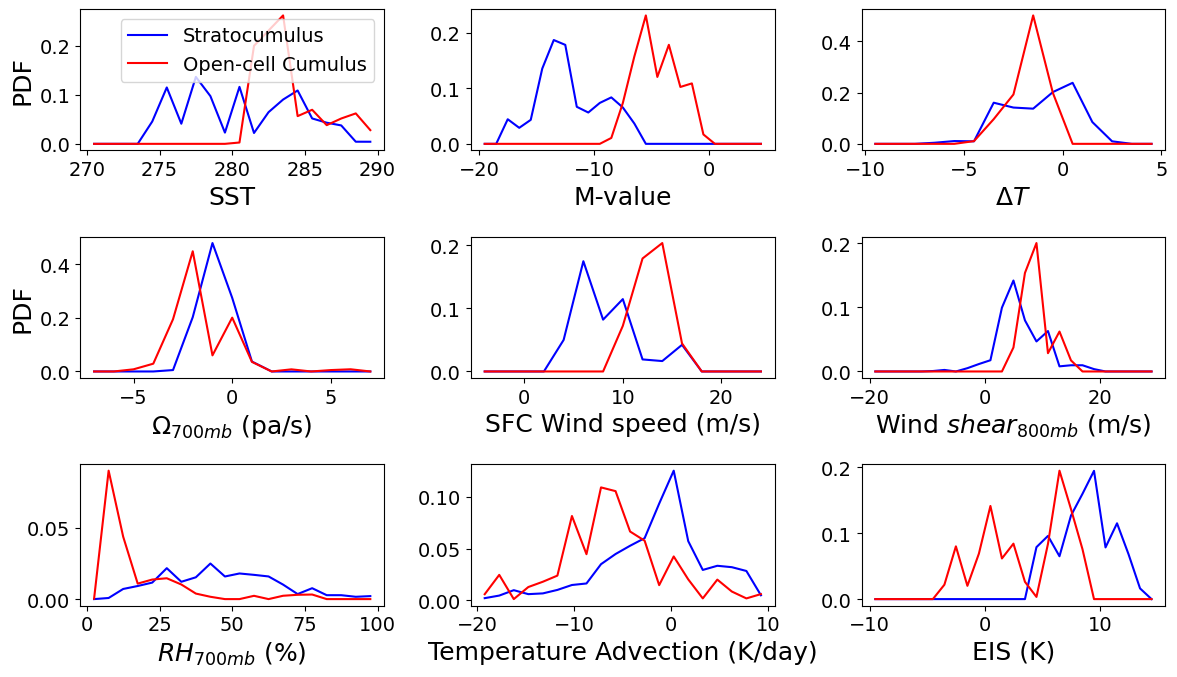

In [109]:
counts = plot_grouped_pdfs(all_fblks)

In [82]:
# plt.savefig('SOCRATES_3x3_PDFs_CCFs_stcu_opcu_013126.png',dpi=300,bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

In [11]:
def plot_joint_pdf(all_fblks, xvar='M', yvar='ws'):
    import numpy as np
    import matplotlib.pyplot as plt
    from datetime import time

    # Helper functions
    def default_inclusion(block, start, end):
        return block.Time.iloc[0].time() > start and block.Time.iloc[-1].time() < end

    def rf12_inclusion(block, start, end):
        return block.Time.iloc[0].time() < start and block.Time.iloc[-1].time() > end

    # Map variable keys to their data field names in blocks
    var_map = {
        'M': 'M',
        'ws': 'Wind_sp',
        'dt': 'deltaT',
        'sst': 'ERA5_SST',
        'omega700': 'omega700',
        'wshear': 'Wind_shear',
        'EIS': 'EIS',
        'Tadv': 'Tadv',
        'RH700': 'RH700'
    }

    # Bin definitions for each variable
    # CSET
    # bins = {
    #     'M': np.linspace(-20, 0, 21),
    #     'ws': np.linspace(-5, 25, 16),
    #     'dt': np.linspace(-10, 6, 17),
    #     'sst': np.linspace(285, 305, 21),
    #     'omega700': np.linspace(-10, 10, 21),
    #     'wshear': np.linspace(-20, 30, 26),
    #     'RH700': np.linspace(0, 100, 21),
    #     'Tadv': np.linspace(-15,15, 31),
    #     'EIS': np.linspace(-5,15,21)
    # }
    # SOCRATES
    bins = {
        'M': np.linspace(-20, 5, 26),
        'ws': np.linspace(-5, 25, 16),
        'dt': np.linspace(-10, 5, 16),
        'sst': np.linspace(270, 290, 21),
        'omega700': np.linspace(-15, 15, 31),
        'wshear': np.linspace(-20, 30, 26),
        'RH700': np.linspace(0, 100, 21),
        'Tadv': np.linspace(-10,10, 21),
        'EIS': np.linspace(-5,20,26)
    }

    if xvar not in var_map or yvar not in var_map:
        raise ValueError(f"xvar and yvar must be among: {list(var_map.keys())}")

    # Flight configurations
    # CSET
    # flight_configs = [
    #     {'flight': 'RF02', 'start': time(15, 30), 'end': time(18, 30), 'group': 'Stratocumulus', 'color': 'blue'},
    #     {'flight': 'RF06', 'start': time(16, 0), 'end': time(18, 0),  'group': 'Stratocumulus', 'color': 'blue'},
    #     {'flight': 'RF10', 'start': time(15, 45), 'end': time(18, 30),  'group': 'Stratocumulus', 'color': 'blue'},
    #     {'flight': 'RF14', 'start': time(15, 45), 'end': time(18, 0),  'group': 'Stratocumulus', 'color': 'blue'},
    #     {'flight': 'RF05', 'start': time(18, 0), 'end': time(22, 0), 'group': 'Open-cell Cumulus', 'color': 'red'},
    #     {'flight': 'RF07', 'start': time(17, 45),  'end': time(22, 15),  'group': 'Open-cell Cumulus', 'color': 'red'},
    #     {'flight': 'RF13', 'start': time(18, 0),  'end': time(23, 0),  'group': 'Open-cell Cumulus', 'color': 'red', 'custom_filter': rf12_inclusion}
    # ]
    # SOCRATES
    flight_configs = [
        {'flight': 'RF13', 'start': time(1, 30), 'end': time(5, 30), 'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF10', 'start': time(0, 0),  'end': time(4, 0),  'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF05', 'start': time(0, 30), 'end': time(3, 0),  'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF15', 'start': time(2, 30), 'end': time(8, 30), 'group': 'Open-cell Cumulus',  'color': 'red'},
        {'flight': 'RF11', 'start': time(2, 45), 'end': time(5, 20), 'group': 'Open-cell Cumulus',  'color': 'red'},
        {'flight': 'RF12', 'start': time(2, 30), 'end': time(5, 30), 'group': 'Open-cell Cumulus',  'color': 'red',
         'custom_filter': rf12_inclusion}
    ]
    # Group container
    group_data = {
        'Stratocumulus': {'x': [], 'y': []},
        'Open-cell Cumulus': {'x': [], 'y': []}
    }

    # Loop over flights
    for cfg in flight_configs:
        blocks = all_fblks[cfg['flight']]
        include_fn = cfg.get('custom_filter', default_inclusion)

        for val in blocks:
            for block in blocks[val]:
                block = block.copy()
                if include_fn(block, cfg['start'], cfg['end']):
                    x_vals = block[var_map[xvar]].values
                    y_vals = block[var_map[yvar]].values
                    mask = ~np.isnan(x_vals) & ~np.isnan(y_vals)
                    group_data[cfg['group']]['x'].append(x_vals[mask])
                    group_data[cfg['group']]['y'].append(y_vals[mask])

    # Plotting
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

    for ax, (label, data) in zip(axes, group_data.items()):
        x = np.concatenate(data['x'])
        y = np.concatenate(data['y'])

        H, xedges, yedges = np.histogram2d(x, y, bins=[bins[xvar], bins[yvar]])
        H = H / H.sum()  # normalize by total count
        H = np.ma.masked_where(H == 0, H)

        pcm = ax.pcolormesh(xedges, yedges, H.T, cmap='YlGnBu_r', vmin=0, vmax=0.2)
        ax.set_title(label)
        ax.set_xlabel(xvar)
        ax.set_ylabel(yvar)
        fig.colorbar(pcm, ax=ax, label='Occurrence Frequency')
        ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
        ax.minorticks_on()

        # Add midpoint reference lines
        x_mid = 0.5 * (xedges[0] + xedges[-1])
        y_mid = 0.5 * (yedges[0] + yedges[-1])
        ax.axhline(y=y_mid, color='red', linestyle='--', linewidth=1)
        ax.axvline(x=x_mid, color='red', linestyle='--', linewidth=1)
        ax.set_xticks(xedges[::5])
        ax.set_yticks(yedges[::5])
        
        
    plt.tight_layout()
    # plt.savefig('CSET_JntPDFs_StCu_OcCu_M_tadv_090925.png', dpi=500, bbox_inches='tight')
    # plt.show()


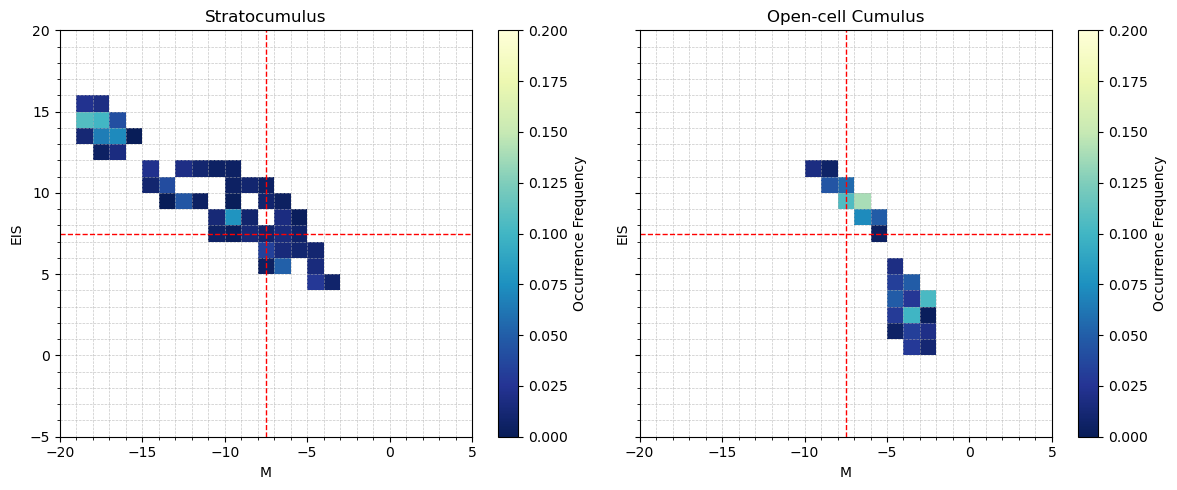

In [17]:
plot_joint_pdf(all_fblks, xvar='M', yvar='EIS')

# Notes for CSET
# M/SST good combo
# M/RH good combo

# Notes for SOCRATES
# M/WS good combo
# M/RH700 good combo
# M/Wshear okay combo
# M/EIS good combo

In [58]:
def plot_joint_pdf(all_fblks, xvar='M', yvar='ws'):
    import numpy as np
    import matplotlib.pyplot as plt
    from datetime import time

    # -------------------------
    # Helper inclusion functions
    # -------------------------
    def default_inclusion(block, start, end):
        return block.Time.iloc[0].time() > start and block.Time.iloc[-1].time() < end

    def rf12_inclusion(block, start, end):
        return block.Time.iloc[0].time() < start and block.Time.iloc[-1].time() > end

    # -------------------------
    # Variable mapping
    # -------------------------
    var_map = {
        'M': 'M',
        'ws': 'Wind_sp',
        'dt': 'deltaT',
        'sst': 'ERA5_SST',
        'omega700': 'omega700',
        'wshear': 'Wind_shear',
        'EIS': 'EIS',
        'Tadv': 'Tadv',
        'RH700': 'RH700'
    }

    # SOCRATES bin definitions
    bins = {
        'M': np.linspace(-20, 5, 26),
        'ws': np.linspace(-5, 25, 16),
        'dt': np.linspace(-10, 5, 16),
        'sst': np.linspace(270, 290, 21),
        'omega700': np.linspace(-15, 15, 31),
        'wshear': np.linspace(-20, 30, 26),
        'RH700': np.linspace(0, 100, 21),
        'Tadv': np.linspace(-10, 10, 21),
        'EIS': np.linspace(-10, 15, 26)
    }

    if xvar not in var_map or yvar not in var_map:
        raise ValueError(f"xvar and yvar must be among: {list(var_map.keys())}")

    # -------------------------
    # Flight configurations (SOCRATES)
    # -------------------------
    flight_configs = [
        {'flight': 'RF13', 'start': time(1, 30), 'end': time(5, 30), 'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF10', 'start': time(0, 0),  'end': time(4, 0),  'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF05', 'start': time(0, 30), 'end': time(3, 0),  'group': 'Stratocumulus',      'color': 'blue'},
        {'flight': 'RF15', 'start': time(2, 30), 'end': time(8, 30), 'group': 'Open-cell Cumulus',  'color': 'red'},
        {'flight': 'RF11', 'start': time(2, 45), 'end': time(5, 20), 'group': 'Open-cell Cumulus',  'color': 'red'},
        {'flight': 'RF12', 'start': time(2, 30), 'end': time(5, 30), 'group': 'Open-cell Cumulus',  'color': 'red',
         'custom_filter': rf12_inclusion}
    ]

    # -------------------------
    # Collect data per group
    # -------------------------
    group_data = {
        'Stratocumulus':      {'x': [], 'y': []},
        'Open-cell Cumulus':  {'x': [], 'y': []},
    }

    for cfg in flight_configs:
        blocks = all_fblks[cfg['flight']]
        include_fn = cfg.get('custom_filter', default_inclusion)

        for val in blocks:
            for block in blocks[val]:
                block = block.copy()
                if include_fn(block, cfg['start'], cfg['end']):
                    x_vals = block[var_map[xvar]].values
                    y_vals = block[var_map[yvar]].values
                    mask = ~np.isnan(x_vals) & ~np.isnan(y_vals)
                    if np.any(mask):
                        group_data[cfg['group']]['x'].append(x_vals[mask])
                        group_data[cfg['group']]['y'].append(y_vals[mask])

    # -------------------------
    # Build histograms first (so we can share color scales)
    # -------------------------
    histograms = {}   # label -> (H_counts, H_freq, xedges, yedges)
    max_count = 0.0
    max_freq  = 0.0

    for label, data in group_data.items():
        if len(data['x']) == 0:
            # no data for this group
            histograms[label] = (None, None, None, None)
            continue

        x = np.concatenate(data['x'])
        y = np.concatenate(data['y'])

        H, xedges, yedges = np.histogram2d(x, y, bins=[bins[xvar], bins[yvar]])
        total = H.sum()
        if total > 0:
            H_freq = H / total
        else:
            H_freq = np.zeros_like(H)

        histograms[label] = (H, H_freq, xedges, yedges)

        max_count = max(max_count, H.max())
        max_freq  = max(max_freq,  H_freq.max())

    # -------------------------
    # 4-panel figure: top row = freq, bottom row = counts
    # -------------------------
    fig, axes = plt.subplots(
        2, 2,
        figsize=(12, 8),
        sharex=True,
        sharey=True
    )

    group_order = ['Stratocumulus', 'Open-cell Cumulus']

    # For adding colorbars after plotting
    pcm_freq_list   = []
    pcm_count_list  = []

    for col, label in enumerate(group_order):
        H, H_freq, xedges, yedges = histograms[label]
        ax_top    = axes[0, col]
        ax_bottom = axes[1, col]

        if H is None:
            ax_top.set_title(f"{label}\n(no data)")
            ax_top.set_visible(False)
            ax_bottom.set_visible(False)
            continue

        # Mask zeros for nicer plotting
        H_freq_masked  = np.ma.masked_where(H_freq == 0, H_freq)
        H_count_masked = np.ma.masked_where(H == 0,      H)

        # ----- Top: normalized frequency -----
        pcm_freq = ax_top.pcolormesh(
            xedges,
            yedges,
            H_freq_masked.T,
            cmap='YlGnBu_r',
            vmin=0,
            vmax=max_freq if max_freq > 0 else 0.2
        )
        pcm_freq_list.append(pcm_freq)

        ax_top.set_title(label)
        ax_top.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
        ax_top.minorticks_on()
        ax_top.set_ylabel(yvar)

        # Add midpoint reference lines (on top row only)
        x_mid = 0.5 * (xedges[0] + xedges[-1])
        y_mid = 0.5 * (yedges[0] + yedges[-1])
        ax_top.axhline(y=y_mid, color='red', linestyle='--', linewidth=1)
        ax_top.axvline(x=x_mid, color='red', linestyle='--', linewidth=1)

        # ----- Bottom: raw counts -----
        pcm_count = ax_bottom.pcolormesh(
            xedges,
            yedges,
            H_count_masked.T,
            cmap='YlOrRd',
            vmin=0,
            vmax=max_count if max_count > 0 else 1
        )
        pcm_count_list.append(pcm_count)

        ax_bottom.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)
        ax_bottom.minorticks_on()
        ax_bottom.set_xlabel(xvar)
        ax_bottom.set_ylabel(yvar)

        # Nice tick spacing (every N bins)
        if len(xedges) > 1:
            ax_top.set_xticks(xedges[::max(1, len(xedges)//6)])
            ax_bottom.set_xticks(xedges[::max(1, len(xedges)//6)])
        if len(yedges) > 1:
            ax_top.set_yticks(yedges[::max(1, len(yedges)//6)])
            ax_bottom.set_yticks(yedges[::max(1, len(yedges)//6)])

    # -------------------------
    # Shared colorbars (one for freq, one for counts)
    # -------------------------
    # top row colorbar
    if pcm_freq_list:
        cbar_freq = fig.colorbar(
            pcm_freq_list[0],
            ax=axes[0, :],
            orientation='vertical',
            fraction=0.046,
            pad=0.02
        )
        cbar_freq.set_label('Occurrence Frequency')

    # bottom row colorbar
    if pcm_count_list:
        cbar_count = fig.colorbar(
            pcm_count_list[0],
            ax=axes[1, :],
            orientation='vertical',
            fraction=0.046,
            pad=0.02
        )
        cbar_count.set_label('Number of Samples')

    fig.suptitle(f"Joint PDFs for {xvar} vs {yvar}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    # plt.savefig('SOCRATES_jointPDF_4panel.png', dpi=400, bbox_inches='tight')
    # plt.show()

    return fig, axes


(<Figure size 1200x800 with 6 Axes>,
 array([[<Axes: title={'center': 'Stratocumulus'}, ylabel='EIS'>,
         <Axes: title={'center': 'Open-cell Cumulus'}, ylabel='EIS'>],
        [<Axes: xlabel='M', ylabel='EIS'>,
         <Axes: xlabel='M', ylabel='EIS'>]], dtype=object))

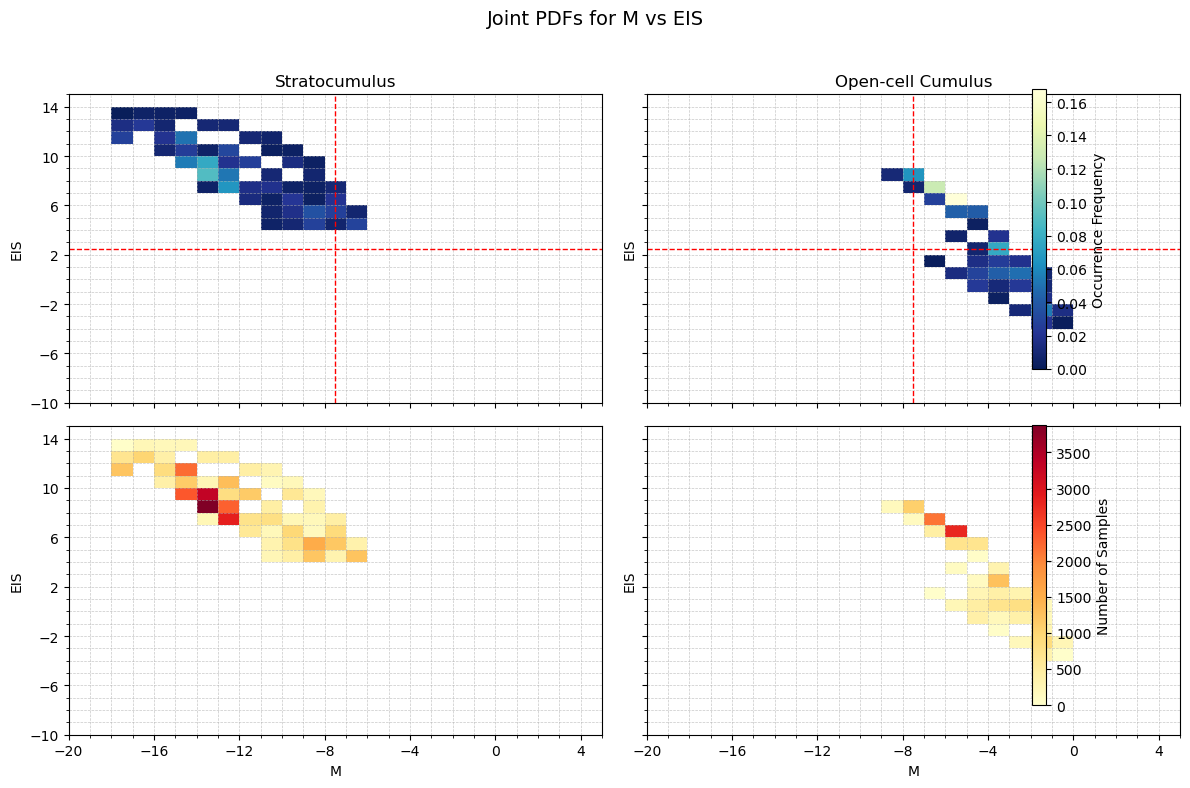

In [59]:
plot_joint_pdf(all_fblks, xvar='M', yvar='EIS')

## test the compositing method comparing the echo-type to the composited data

In [90]:
def load_nc_cldrgme(file_paths):
    
    combined_blocks = []   
    for path in file_paths:
        rf = path.split("/")[-1].split(".")[0]  # e.g., "RF01"
        ds = xr.open_dataset(path)
        
        # Get unique combinations
        labels = ds["block_label"].values
        indices = ds["block_index"].values
        
        # Convert to DataFrame for convenient filtering
        df = ds.to_dataframe().reset_index().drop(columns="index")  # remove redundant index
        
        # Get all unique (label, index) pairs
        unique_blocks = df[["block_label", "block_index"]].drop_duplicates()
        
        # Loop through each unique block
        for _, row in unique_blocks.iterrows():
            label = row["block_label"]
            idx = row["block_index"]
        
            # Filter DataFrame
            df_block = df[(df["block_label"] == label) & (df["block_index"] == idx)].copy()
        
            # (Optional) add flight ID if you have it
            df_block["block_label"] = label
            df_block["block_index"] = idx
        
            combined_blocks.append(df_block)
        all_blocks = pd.concat(combined_blocks, ignore_index=True)
    return all_blocks
# Path to your NetCDF files (adjust as needed)
file_paths = sorted(glob.glob("/glade/u/home/patnaude/inform/composited data/*SOCRATES*.nc"))
All_rf_df = load_nc_cldrgme(file_paths)

Processing HCR files: 100%|██████████| 31/31 [00:21<00:00,  1.44it/s]


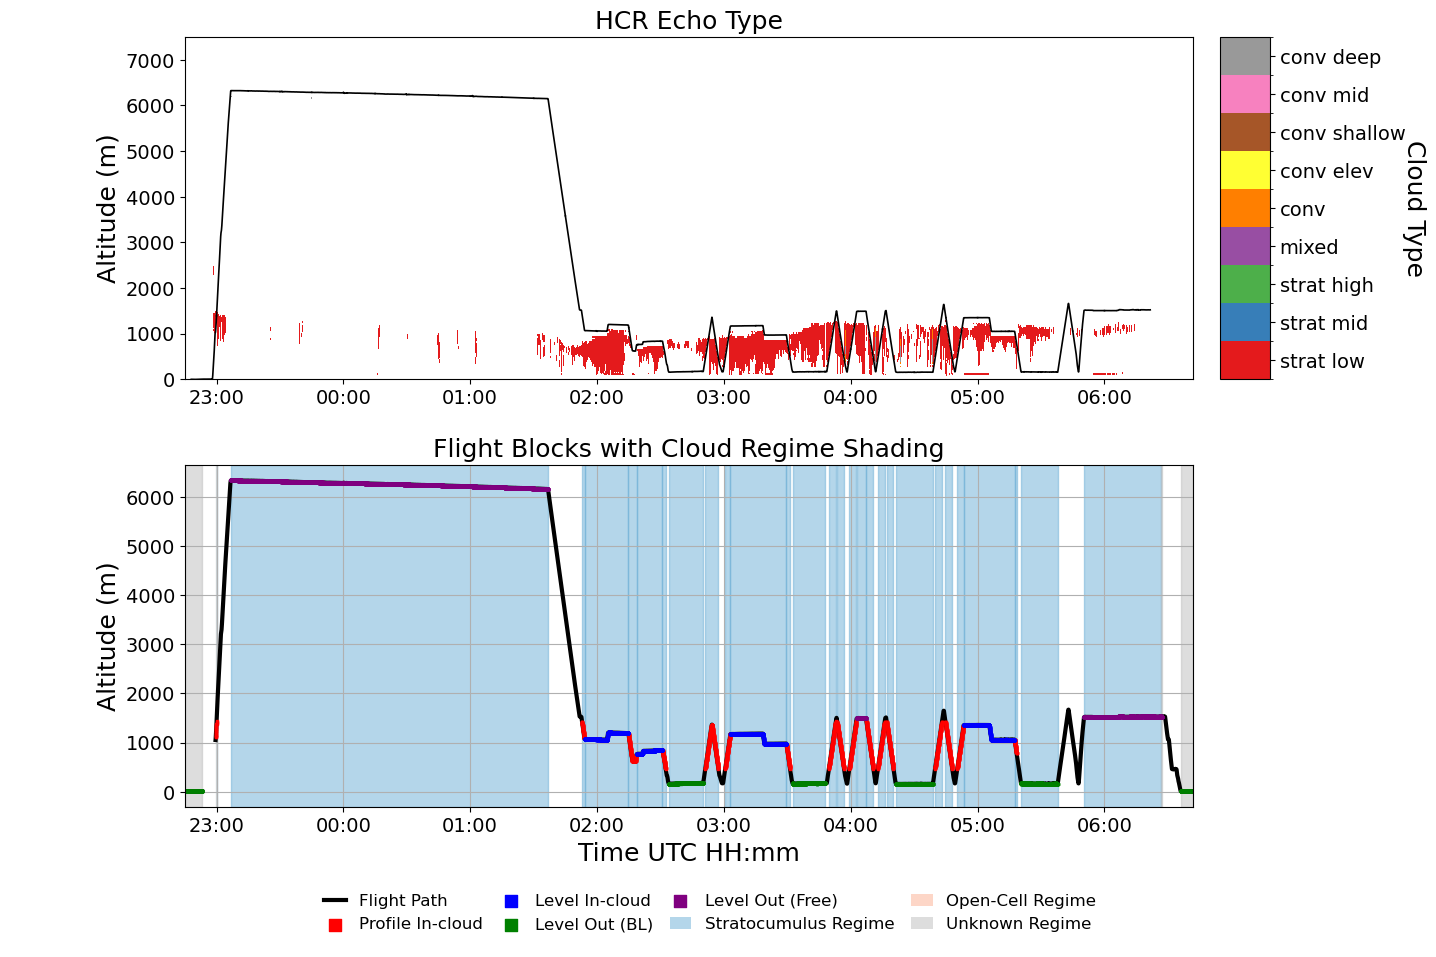

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.dates as mdates
from matplotlib import gridspec
from tqdm import tqdm
import gc

# Clean up old figures / objects
plt.close('all')
gc.collect()

# ============================
# USER INPUT: choose flight #
# ============================
flight_number = 13
rf_id = f"RF{flight_number:02d}"
# ============================
# PATHS THAT UPDATE AUTOMATICALLY
# ============================

# HCR radar files
dir_hcr = f'/glade/work/patnaude/SOCRATES/hcr_hsrl/{rf_id}/'
flight_paths = inform.find_flight_fnames(dir_hcr)

# Aircraft 1 Hz data
campaign = "SOCRATES"

ccn_df = inform.load_ccn_for_campaign(campaign)  # loads once

dir_ac = '/glade/work/patnaude/SOCRATES/aircraft_1hz/'
df = inform.load_flight_data(campaign, flight_number - 1,ccn_df=ccn_df)

# Apply your block/type classification
flight_dict = pdp.assign_flight_type(df)

df = flight_dict['DataFrame']
blocks = flight_dict['flight_blocks']

# Regime blocks from the master table
regime_blocks = All_rf_df[All_rf_df['flight'] == rf_id].copy()

df['Time'] = pd.to_datetime(df['Time'])

plt.rcParams.update({
    "font.size": 14,          # base text size
    "axes.labelsize": 18,     # x/y labels
    "axes.titlesize": 18,     # titles
    "xtick.labelsize": 14,    # x-axis tick labels
    "ytick.labelsize": 14,    # y-axis tick labels
    "legend.fontsize": 14,    # legend text
})

# --------------------------------------------------
# Figure + GridSpec Layout
# --------------------------------------------------
fig = plt.figure(figsize=(14, 10))
gs = gridspec.GridSpec(
    2, 2,
    width_ratios=[20, 1],
    height_ratios=[1, 1],
    wspace=0.05,
    hspace=0.25
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)
cax1 = fig.add_subplot(gs[0, 1])
ax_empty = fig.add_subplot(gs[1, 1])
ax_empty.axis('off')

# --------------------------------------------------
# PANEL 1 — HCR Echo Type
# --------------------------------------------------
time_stride = 2
range_stride = 2
valid_codes = np.array([14, 16, 18, 25, 30, 32, 34, 36, 38], dtype='int16')

for file in tqdm(flight_paths, desc="Processing HCR files"):
    nc = inform.open_nc(file)

    time      = np.array(nc.time)[::time_stride]
    alt       = np.array(nc.altitude)[::time_stride]
    range_    = np.array(nc.range)[::range_stride]
    elevation = np.array(nc.elevation)[::time_stride]

    time = pd.to_datetime(time).to_numpy()

    echo_vars = [var for var in nc.data_vars if 'ECHO_TYPE_2D' in var]
    if not echo_vars:
        nc.close()
        continue

    echo_da = nc[echo_vars[0]].isel(
        time=slice(None, None, time_stride),
        range=slice(None, None, range_stride),
    ).astype('int16')

    echo = echo_da.values

    mask_valid = np.isin(echo, valid_codes)
    echo = np.where(mask_valid, echo, np.nan)

    echo_flipped = echo[:, ::-1]
    range_flipped = range_[::-1]

    az_mask = (elevation > 0).astype(int)[:, np.newaxis]
    range_signed = np.where(az_mask, range_flipped, -range_flipped)

    alt_grid  = np.tile(alt[:, np.newaxis], (1, len(range_flipped))) + range_signed
    time_grid = np.tile(time[:, np.newaxis], (1, len(range_flipped)))

    im1 = ax1.pcolormesh(time_grid, alt_grid, echo_flipped,
                         cmap='Set1', shading='auto')
    ax1.plot(time, alt, color='black', linewidth=1.2)

    nc.close()
    del echo_da, echo, echo_flipped, range_flipped, range_signed, alt_grid, time_grid
    gc.collect()

ax1.set_ylabel("Altitude (m)")
ax1.set_title("HCR Echo Type")
ax1.set_ylim(0, 7500)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
# --------------------------------------------------
# PANEL 2 — Altitude w/ Regime Shading
# --------------------------------------------------
profile_in_cloud = df[(df['flight_type'] == 'profile') &
                      (df['cloud_status'] == 'In-cloud')]
level_in_cloud = df[(df['flight_type'] == 'level') &
                    (df['cloud_status'] == 'In-cloud') &
                    (df['Location'] != 'BL')]
level_out_bl = df[(df['flight_type'] == 'level') &
                  (df['cloud_status'] != 'In-cloud') &
                  (df['Location'] == 'BL')]
level_out_fr = df[(df['flight_type'] == 'level') &
                  (df['cloud_status'] != 'In-cloud') &
                  (df['Location'] == 'Free')]

ax2.plot(df['Time'], df['GGALT'], color='k', linewidth=3, label='Flight Path')

ax2.scatter(profile_in_cloud['Time'], profile_in_cloud['GGALT'],
            color='red', marker='s', s=4, label='Profile In-cloud',zorder=2)

ax2.scatter(level_in_cloud['Time'], level_in_cloud['GGALT'],
            color='blue', marker='s', s=4, label='Level In-cloud',zorder=2)

ax2.scatter(level_out_bl['Time'], level_out_bl['GGALT'],
            color='green', marker='s', s=4, label='Level Out (BL)',zorder=2)

ax2.scatter(level_out_fr['Time'], level_out_fr['GGALT'],
            color='purple', marker='s', s=4, label='Level Out (Free)',zorder=2)

regime_colors = {
    'Stratocumulus': "#6baed6",
    'Open-Cell': "#fcae91",
    'Undetermined': "#bdbdbd",
}

regime_spans = (regime_blocks
                .groupby(["cloud_regime", "block_label", "block_index"])
                .agg(start_time=("Time", "min"),
                     end_time=("Time", "max"))
                .reset_index()
                .sort_values("start_time"))

for _, row in regime_spans.iterrows():
    ax2.axvspan(row['start_time'], row['end_time'],
                color=regime_colors.get(row['cloud_regime'], "lightgrey"),
                alpha=0.5, zorder=0)

ax2.set_ylabel("Altitude (m)")
ax2.set_title("Flight Blocks with Cloud Regime Shading")
ax2.grid(True)

# --------------------------------------------------
# COLORBAR (only for panel 1)
# --------------------------------------------------
tick_values = [14, 16, 18, 25, 30, 32, 34, 36, 38]
tick_labels = [
    "strat low", "strat mid", "strat high",
    "mixed", "conv", "conv elev",
    "conv shallow", "conv mid", "conv deep"
]
colors = plt.get_cmap("Set1")(np.linspace(0, 1, len(tick_values)))
norm = BoundaryNorm(list(range(len(tick_values) + 1)), len(tick_values))
cmap = ListedColormap(colors)

cbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cax1,
    orientation='vertical',
    ticks=np.arange(len(tick_values)) + 0.5
)
cbar.ax.set_yticklabels(tick_labels)
cbar.set_label("Cloud Type", rotation=270, labelpad=15)

# --------------------------------------------------
# MATCH X LIMITS
# --------------------------------------------------
xmin, xmax = df["Time"].min(), df["Time"].max()
ax1.set_xlim(xmin, xmax)
ax2.set_xlim(xmin, xmax)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax2.set_xlabel('Time UTC HH:mm')
# --------------------------------------------------
# BOTTOM LEGEND (8 columns, full width; includes shading)
# --------------------------------------------------

from matplotlib.patches import Patch

# Create invisible axis at bottom
legend_ax = fig.add_axes([0, -0.03, 1, 0.12])   # adjust height as needed
legend_ax.axis('off')

# 1. Get point-legend handles from panel 2
pt_handles, pt_labels = ax2.get_legend_handles_labels()

# 2. Create shading proxy artists for regimes
regime_handles = [
    Patch(facecolor="#6baed6", alpha=0.5, label="Stratocumulus Regime"),
    Patch(facecolor="#fcae91", alpha=0.5, label="Open-Cell Regime"),
    Patch(facecolor="#bdbdbd", alpha=0.5, label="Unknown Regime"),
]

# 3. Combine point and shading legends
all_handles = pt_handles + regime_handles
all_labels  = pt_labels  + [h.get_label() for h in regime_handles]

# 4. Draw bottom legend
legend_ax.legend(
    all_handles, all_labels,
    loc='lower center',
    ncol=4,
    fontsize=12,
    frameon=False,
    columnspacing=1.0,
    handlelength=1.3,
    markerscale=4
)

fig.tight_layout()

# plt.savefig(f'SOCRATES_echotype_blocks_regime_{rf_id}.png',dpi=300,bbox_inches='tight')


In [104]:
fig.savefig(f'SOCRATES_echotype_blocks_regime_{rf_id}.png',dpi=300,bbox_inches='tight')


In [97]:
nc

<xarray.Dataset> Size: 381MB
Dimensions:                 (Time: 26091, sps1: 1, Vector64: 64, Vector31: 31,
                             Vector63: 63, Vector100: 100, Vector129: 129,
                             interarrival_endpoints: 41, Vector257: 257)
Coordinates:
  * Time                    (Time) datetime64[ns] 209kB 2018-01-15T22:50:00 ....
  * interarrival_endpoints  (interarrival_endpoints) float32 164B 1e-07 ... 10.0
Dimensions without coordinates: sps1, Vector64, Vector31, Vector63, Vector100,
                                Vector129, Vector257
Data variables: (12/265)
    A1DC_RWOI               (Time, sps1, Vector64) float32 7MB ...
    ACDP_RWIO               (Time, sps1, Vector31) float32 3MB ...
    ACINS                   (Time) float32 104kB ...
    ADIFR                   (Time) float32 104kB ...
    ALT                     (Time) float32 104kB ...
    APIP_RWII               (Time, sps1, Vector63) float32 7MB ...
    ...                      ...
    REFF2DSR_2V             (Time) float32 104kB ...
    REFF2DSA_2V             (Time) float32 104kB ...
    NACCEPT2DSR_2V          (Time) float32 104kB ...
    NACCEPT2DSA_2V          (Time) float32 104kB ...
    NREJECT2DSR_2V          (Time) float32 104kB ...
    NREJECT2DSA_2V          (Time) float32 104kB ...
Attributes: (12/38)
    institution:                   NCAR Research Aviation Facility
    Address:                       P.O. Box 3000, Boulder, CO 80307-3000
    Phone:                         (303) 497-1030
    creator_url:                   http://www.eol.ucar.edu
    creator_email:                 codiac at ucar.edu
    Conventions:                   NCAR-RAF/nimbus
    ...                            ...
    geospatial_vertical_units:     m
    wind_field:                    WSC WDC WIC
    landmarks:                     39.9088 -105.117 jeffco
    Categories:                    Position,Thermodynamic,Aircraft State,Atmo...
    time_coverage_start:           2018-01-15T22:50:00 +0000
    time_coverage_end:             2018-01-16T06:04:50 +0000